In [2]:
import arff
import pandas as pd


with open("../data/AmesHousing.arff", "r") as file:
    dataset = arff.load(file)

df = pd.DataFrame(
    dataset["data"],
    columns=[attribute[0] for attribute in dataset["attributes"]]
)

print("Shape:", df.shape)
display(df.head())

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


# **DATA EXPLORATION**

In [3]:
print(df.columns.tolist())
print(df.info())
print(df.isnull().sum().sort_values(ascending=False).head(20))

['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC'

In [4]:
missing = df.isnull().sum()
missing = missing[missing>0].sort_values(ascending=False)

missing_df = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df) * 100).round(2)
})

display(missing_df)

,Missing_Count,Missing_Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55
GarageQual,81,5.55


In [5]:
print(df["SalePrice"].describe())

print("Minimum price:", df["SalePrice"].min())
print("Maximum price:", df["SalePrice"].max())
print("Average price:", df["SalePrice"].mean())
print("Median price:", df["SalePrice"].median())

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64
Minimum price: 34900
Maximum price: 755000
Average price: 180921.19589041095
Median price: 163000.0


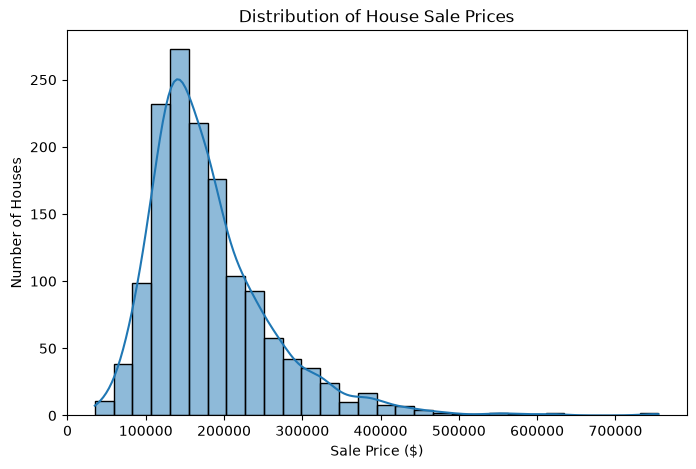

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df["SalePrice"], bins=30, kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")
plt.show()

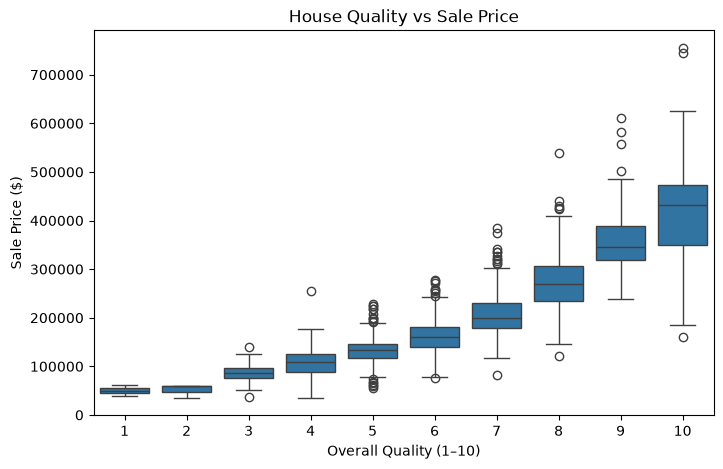

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="OverallQual", y="SalePrice")

plt.title("House Quality vs Sale Price")
plt.xlabel("Overall Quality (1–10)")
plt.ylabel("Sale Price ($)")

plt.show()

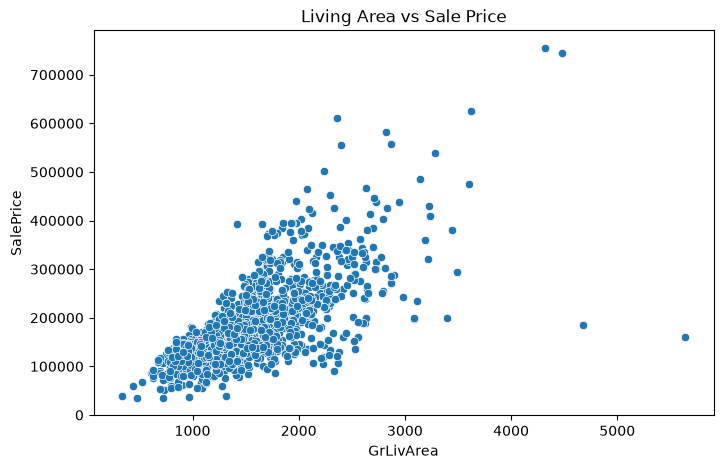

In [8]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice")
plt.title("Living Area vs Sale Price")
plt.show()

In [9]:
correlations = df.select_dtypes(include="number").corr()["SalePrice"]
print(correlations.sort_values(ascending=False))

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

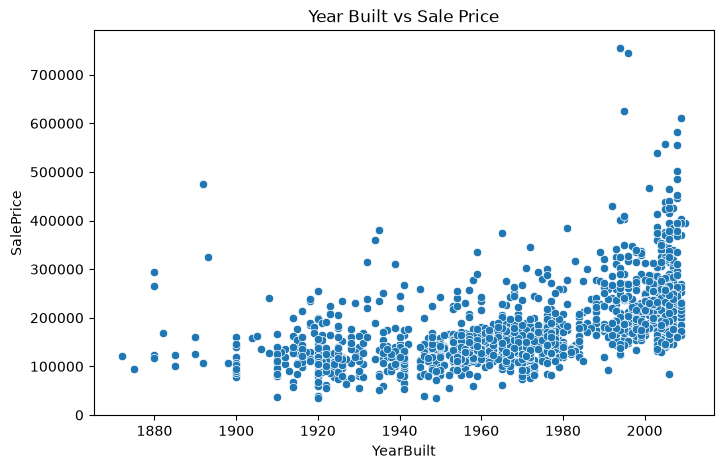

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="YearBuilt", y="SalePrice")
plt.title("Year Built vs Sale Price")
plt.show()

In [11]:
print(df["YearBuilt"].corr(df["SalePrice"]))

0.522897332879497


# **DATA PREPROCESSING**

In [12]:
print("Duplicate rows:", df.duplicated().sum())

print(df.dtypes.value_counts())

print("Missing SalePrice:", df["SalePrice"].isnull().sum())

for col in ["MSZoning", "Street", "Neighborhood", "HouseStyle"]:
    print('\n',df[col].value_counts().head())

Duplicate rows: 0
str        43
int64      35
float64     3
Name: count, dtype: int64
Missing SalePrice: 0

 MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

 Street
Pave    1454
Grvl       6
Name: count, dtype: int64

 Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Name: count, dtype: int64

 HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
Name: count, dtype: int64


In [13]:
# Missing-value counts and percentages
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing_df = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df) * 100).round(2)
})

display(missing_df)

,Missing_Count,Missing_Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55
GarageQual,81,5.55


In [14]:
columns_to_check = [
    "PoolQC", "MiscFeature", "Alley",
    "Fence", "FireplaceQu", "LotFrontage"
]

for col in columns_to_check:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print("Missing:", df[col].isnull().sum())
        print(df[col].value_counts(dropna=False).head(8))


--- PoolQC ---
Missing: 1453
PoolQC
NaN    1453
Gd        3
Ex        2
Fa        2
Name: count, dtype: int64

--- MiscFeature ---
Missing: 1406
MiscFeature
NaN     1406
Shed      49
Gar2       2
Othr       2
TenC       1
Name: count, dtype: int64

--- Alley ---
Missing: 1369
Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64

--- Fence ---
Missing: 1179
Fence
NaN      1179
MnPrv     157
GdPrv      59
GdWo       54
MnWw       11
Name: count, dtype: int64

--- FireplaceQu ---
Missing: 690
FireplaceQu
NaN    690
Gd     380
TA     313
Fa      33
Ex      24
Po      20
Name: count, dtype: int64

--- LotFrontage ---
Missing: 259
LotFrontage
NaN     259
60.0    143
70.0     70
80.0     69
50.0     57
75.0     53
65.0     44
85.0     40
Name: count, dtype: int64


### First Pipeline to Handle Missing Categorical features 

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns=["SalePrice", "Id"])
y = df["SalePrice"]

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant", fill_value="None"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)
print("Missing values in training data:", X_train.isnull().sum().sum())

Original training shape: (1168, 79)
Processed training shape: (1168, 301)
Processed test shape: (292, 301)
Missing values in training data: 5550


# **LINEAR REGRESSION**

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


model = LinearRegression()
model.fit(X_train_processed, y_train)

predictions = model.predict(X_test_processed)
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R-squared:", r2)

Mean Absolute Error: 21126.193674308346
Mean Squared Error: 4275549353.853906
Root Mean Squared Error: 65387.68503207547
R-squared: 0.4425857208201003


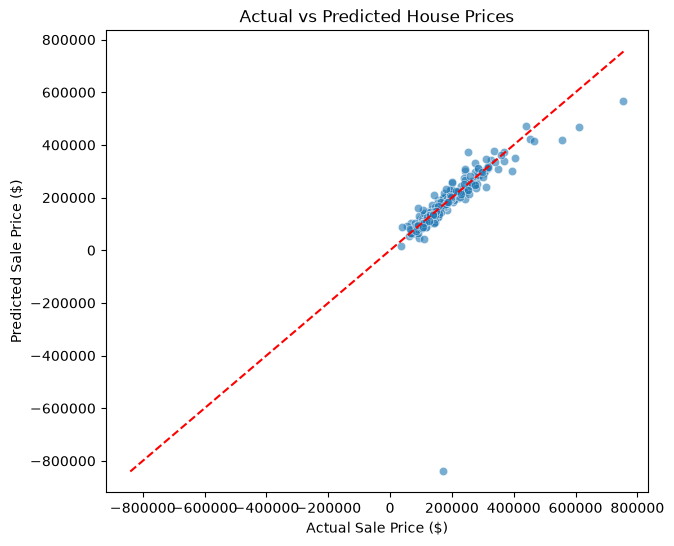

In [17]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=predictions, alpha=0.6)

# Perfect prediction line
low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())
plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.title("Actual vs Predicted House Prices")
plt.show()

In [18]:
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": predictions,
})

results["Error"] = results["Actual"] - results["Predicted"]
results["AbsoluteError"] = results["Error"].abs()

display(
    results.sort_values("AbsoluteError", ascending=False).head(10)
)

,Actual,Predicted,Error,AbsoluteError
193,171000,-840346.393521,1.011346e+06,1.011346e+06
139,755000,568365.462484,1.866345e+05,1.866345e+05
74,611657,468278.067353,1.433789e+05,1.433789e+05
168,556581,420703.553091,1.358774e+05,1.358774e+05
43,253293,372755.336809,-1.194623e+05,1.194623e+05
260,395000,300575.351532,9.442465e+04,9.442465e+04
6,311500,239627.805001,7.187219e+04,7.187219e+04
287,89471,159819.018410,-7.034802e+04,7.034802e+04
278,143000,209231.051058,-6.623105e+04,6.623105e+04
191,108480,42336.141215,6.614386e+04,6.614386e+04


In [19]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_processed, y_train)

baseline_predictions = baseline.predict(X_test_processed)

print("Baseline MAE:",
      mean_absolute_error(y_test, baseline_predictions))
print("Baseline R²:",
      r2_score(y_test, baseline_predictions))

Baseline MAE: 62575.926451960964
Baseline R²: -0.0008824918802490256


Needs Improvement

In [20]:
# Position of the largest absolute prediction error
worst_pos = results["AbsoluteError"].to_numpy().argmax()

# Get the corresponding original test row by position
print("Actual price:", y_test.iloc[worst_pos])
print("Predicted price:", predictions[worst_pos])

display(X_test.iloc[[worst_pos]].T)

Actual price: 171000
Predicted price: -840346.3935209366


,1170
MSSubClass,80
MSZoning,RL
LotFrontage,76.0
LotArea,9880
Street,Pave
...,...
MiscVal,0
MoSold,7
YrSold,2008
SaleType,WD


In [21]:
# Transform this house using the already-fitted preprocessor
worst_house = X_test.iloc[[worst_pos]]
worst_transformed = preprocessor.transform(worst_house)

# Get the fitted Linear Regression model's contributions
feature_names = preprocessor.get_feature_names_out()
coefficients = model.coef_

if hasattr(worst_transformed, "toarray"):
    values = worst_transformed.toarray()[0]
else:
    values = worst_transformed[0]

contributions = pd.DataFrame({
    "Feature": feature_names,
    "Value": values,
    "Coefficient": coefficients,
    "Contribution": values * coefficients
})

display(
    contributions.reindex(
        contributions["Contribution"].abs()
        .sort_values(ascending=False).index
    ).head(15)
)

print("Model intercept:", model.intercept_)
print("Sum of contributions:", contributions["Contribution"].sum())
print("Predicted price:", model.predict(worst_transformed)[0])

,Feature,Value,Coefficient,Contribution
32,num__PoolArea,13.76496,2.644685e+05,3.640398e+06
274,cat__PoolQC_Gd,1.00000,-1.631763e+06,-1.631763e+06
282,cat__MiscFeature_None,1.00000,-1.485469e+05,-1.485469e+05
126,cat__RoofMatl_CompShg,1.00000,-1.422696e+05,-1.422696e+05
100,cat__Condition2_Norm,1.00000,3.380320e+04,3.380320e+04
268,cat__GarageCond_TA,1.00000,2.944052e+04,2.944052e+04
262,cat__GarageQual_TA,1.00000,-2.671116e+04,-2.671116e+04
239,cat__Functional_Typ,1.00000,2.182456e+04,2.182456e+04
54,cat__Utilities_AllPub,1.00000,1.883941e+04,1.883941e+04
120,cat__RoofStyle_Gable,1.00000,-1.880686e+04,-1.880686e+04


Model intercept: -2578037.709720656
Sum of contributions: 1737691.3161997187
Predicted price: -840346.3935209366


## RIDGE REGRESSION

In [22]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

for alpha in [1, 10, 100]:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_processed, y_train)

    ridge_predictions = ridge.predict(X_test_processed)

    mae = mean_absolute_error(y_test, ridge_predictions)
    rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
    r2 = r2_score(y_test, ridge_predictions)

    print(f"\nAlpha: {alpha}")
    print(f"MAE:  ${mae:,.2f}")
    print(f"RMSE: ${rmse:,.2f}")
    print(f"R²:    {r2:.4f}")


Alpha: 1
MAE:  $19,122.35
RMSE: $29,736.36
R²:    0.8847

Alpha: 10
MAE:  $19,178.84
RMSE: $30,524.61
R²:    0.8785

Alpha: 100
MAE:  $18,735.15
RMSE: $32,305.18
R²:    0.8639


In [23]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Keep preprocessing inside the pipeline
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

search = GridSearchCV(
    ridge_pipeline,
    param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best alpha:", search.best_params_["model__alpha"])
print("Best CV MAE:", -search.best_score_)

best_model = search.best_estimator_
final_predictions = best_model.predict(X_test)

print("Test MAE:", mean_absolute_error(y_test, final_predictions))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, final_predictions)))
print("Test R²:", r2_score(y_test, final_predictions))

Best alpha: 10
Best CV MAE: 18172.754533630556
Test MAE: 19178.838064328786
Test RMSE: 30524.614164395203
Test R²: 0.878525105097598
